# Customer Churn Analysis
### Exploratory Data Analysis (EDA) | Python

**Objective:** Explore customer churn patterns and identify customer segments or service experiences that may warrant retention attention.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Dataset:** Telco-style customer churn data (`Customer Churn (1).csv`)

> **How to run:** Place the CSV file in the same folder as this notebook, then run the cells from top to bottom. The notebook performs descriptive analysis only; it does not train a predictive model or establish causation.

## 1. Business questions

- What share of customers have churned?
- How does churn vary by contract type, tenure, internet service and payment method?
- Are optional support and protection services associated with different churn patterns?
- Which practical retention actions should the business investigate?

In [4]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = Path("Customer Churn (1) .csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Put 'Customer Churn (1) .csv' in the same folder as this notebook "
        "or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data quality and preparation

The original notebook recorded **7,043 rows and 21 columns**, no duplicate `customerID` values, and blank `TotalCharges` entries represented as spaces. The preparation below converts those spaces to missing values before numeric conversion, then fills the resulting values with zero only for the zero-tenure/no-charge records. Review this assumption if using a different version of the dataset.

In [5]:
# Standardise column labels and trim whitespace in text fields.
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

required_columns = {
    "customerID", "gender", "SeniorCitizen", "tenure", "Contract",
    "InternetService", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {sorted(missing_columns)}")

# Convert TotalCharges safely: blank strings become NaN, then numeric.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

# In the source notebook, blank TotalCharges corresponded to new customers
# with zero tenure. Keep that explicit and inspect before filling.
blank_total_charges = int(df["TotalCharges"].isna().sum())
zero_tenure_blank_charges = int(
    (df["TotalCharges"].isna() & (pd.to_numeric(df["tenure"], errors="coerce") == 0)).sum()
)
print(f"Blank/unparseable TotalCharges before handling: {blank_total_charges}")
print(f"Those with zero tenure: {zero_tenure_blank_charges}")

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["tenure"] = pd.to_numeric(df["tenure"], errors="coerce")
df["MonthlyCharges"] = pd.to_numeric(df["MonthlyCharges"], errors="coerce")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna(df["SeniorCitizen"].astype(str))

print("\nMissing values after preparation:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values").head(10))
print(f"Duplicate customer IDs: {df['customerID'].duplicated().sum():,}")

Blank/unparseable TotalCharges before handling: 11
Those with zero tenure: 11

Missing values after preparation:


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10880\1034955358.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate customer IDs: 0


## 3. Dataset overview

Use the summary tables to check distributions and data types before interpreting the charts.

In [6]:
display(df.dtypes.rename("dtype").to_frame())
display(df.describe(include="all").T)

,dtype
customerID,str
gender,str
SeniorCitizen,str
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043,2,No,5901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,"7,043.00",NaN,NaN,NaN,32.37,24.56,0.00,9.00,29.00,55.00,72.00
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Overall churn

The churn rate is the proportion of customers whose `Churn` value is `Yes`. Always show the rate alongside counts so that the business impact is easy to interpret.

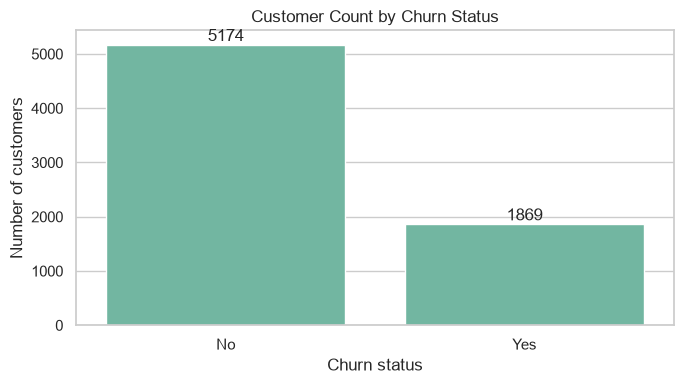

Overall churn rate: 26.54%


,Customers
Churn,
No,5174
Yes,1869


In [7]:
churn_counts = df["Churn"].value_counts(dropna=False)
churn_rate = df["Churn"].eq("Yes").mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], ax=ax)
ax.set(title="Customer Count by Churn Status", xlabel="Churn status", ylabel="Number of customers")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

print(f"Overall churn rate: {churn_rate:.2f}%")
display(churn_counts.rename_axis("Churn").to_frame("Customers"))

## 5. Churn by customer profile

Compare **within-group churn rates**, rather than relying only on raw counts. Larger groups naturally tend to have larger counts.


gender: churn rate within each group


Churn,Stayed (%),Churned (%)
gender,,
Female,73.08,26.92
Male,73.84,26.16



SeniorCitizen: churn rate within each group


Churn,Stayed (%),Churned (%)
SeniorCitizen,,
Yes,58.32,41.68
No,76.39,23.61



Partner: churn rate within each group


Churn,Stayed (%),Churned (%)
Partner,,
No,67.04,32.96
Yes,80.34,19.66



Dependents: churn rate within each group


Churn,Stayed (%),Churned (%)
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


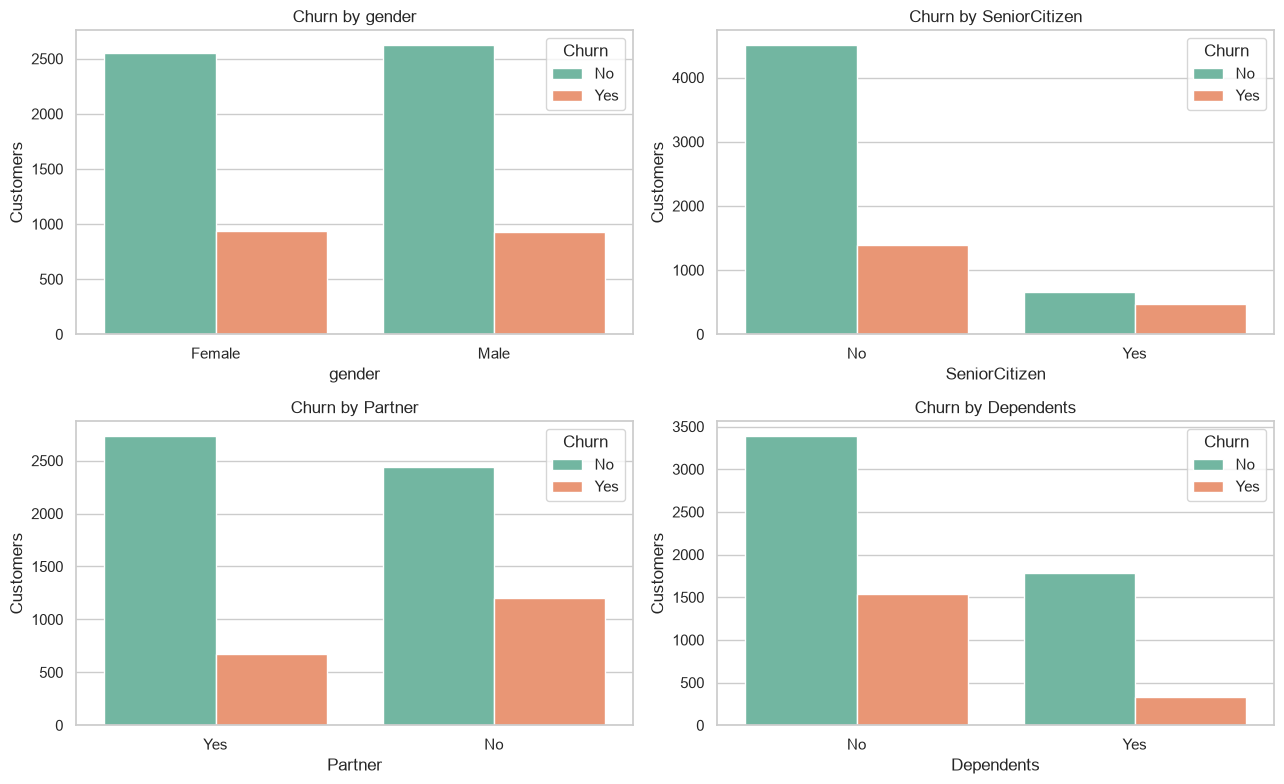

In [8]:
def churn_rate_table(data, feature):
    out = pd.crosstab(data[feature], data["Churn"], normalize="index") * 100
    if "Yes" not in out.columns:
        out["Yes"] = 0.0
    return out.sort_values("Yes", ascending=False).rename(columns={"No": "Stayed (%)", "Yes": "Churned (%)"})

for feature in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    if feature in df.columns:
        print(f"\n{feature}: churn rate within each group")
        display(churn_rate_table(df, feature).round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, feature in zip(axes.flat, ["gender", "SeniorCitizen", "Partner", "Dependents"]):
    if feature in df.columns:
        sns.countplot(data=df, x=feature, hue="Churn", ax=ax)
        ax.set_title(f"Churn by {feature}")
        ax.set_xlabel(feature)
        ax.set_ylabel("Customers")
        ax.legend(title="Churn")
plt.tight_layout()
plt.show()

## 6. Tenure and contract type

Tenure and contract structure are key areas to inspect because they describe how long a customer has stayed and the flexibility of their agreement.

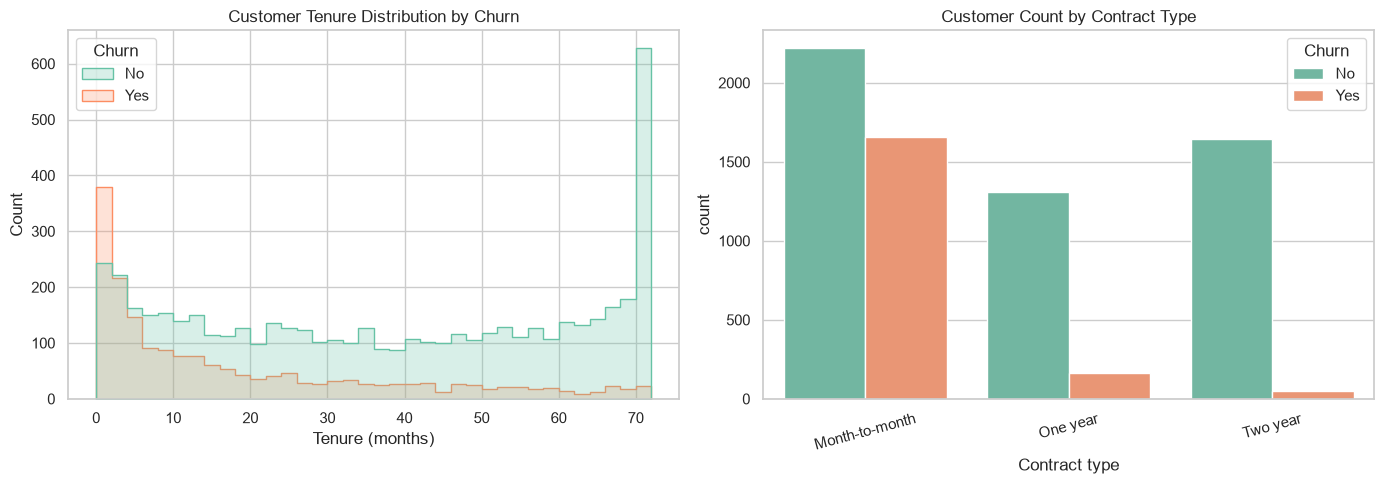

Churn rate by contract type:


Churn,Stayed (%),Churned (%)
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Churn rate by tenure band:


Churn,Stayed (%),Churned (%)
TenureBand,,
0–6 months,47.06,52.94
7–12 months,64.11,35.89
13–24 months,71.29,28.71
25–48 months,79.61,20.39
49–72 months,90.49,9.51


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, element="step",
             stat="count", common_norm=False, ax=axes[0])
axes[0].set_title("Customer Tenure Distribution by Churn")
axes[0].set_xlabel("Tenure (months)")

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1])
axes[1].set_title("Customer Count by Contract Type")
axes[1].tick_params(axis="x", rotation=15)
axes[1].set_xlabel("Contract type")
plt.tight_layout()
plt.show()

print("Churn rate by contract type:")
display(churn_rate_table(df, "Contract").round(2))

print("Churn rate by tenure band:")
df["TenureBand"] = pd.cut(
    df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
)
display(churn_rate_table(df, "TenureBand").round(2))

## 7. Internet and value-added services

These charts compare churn outcomes across internet products, support and protection services. Treat the patterns as associations, not proof that a service causes retention.

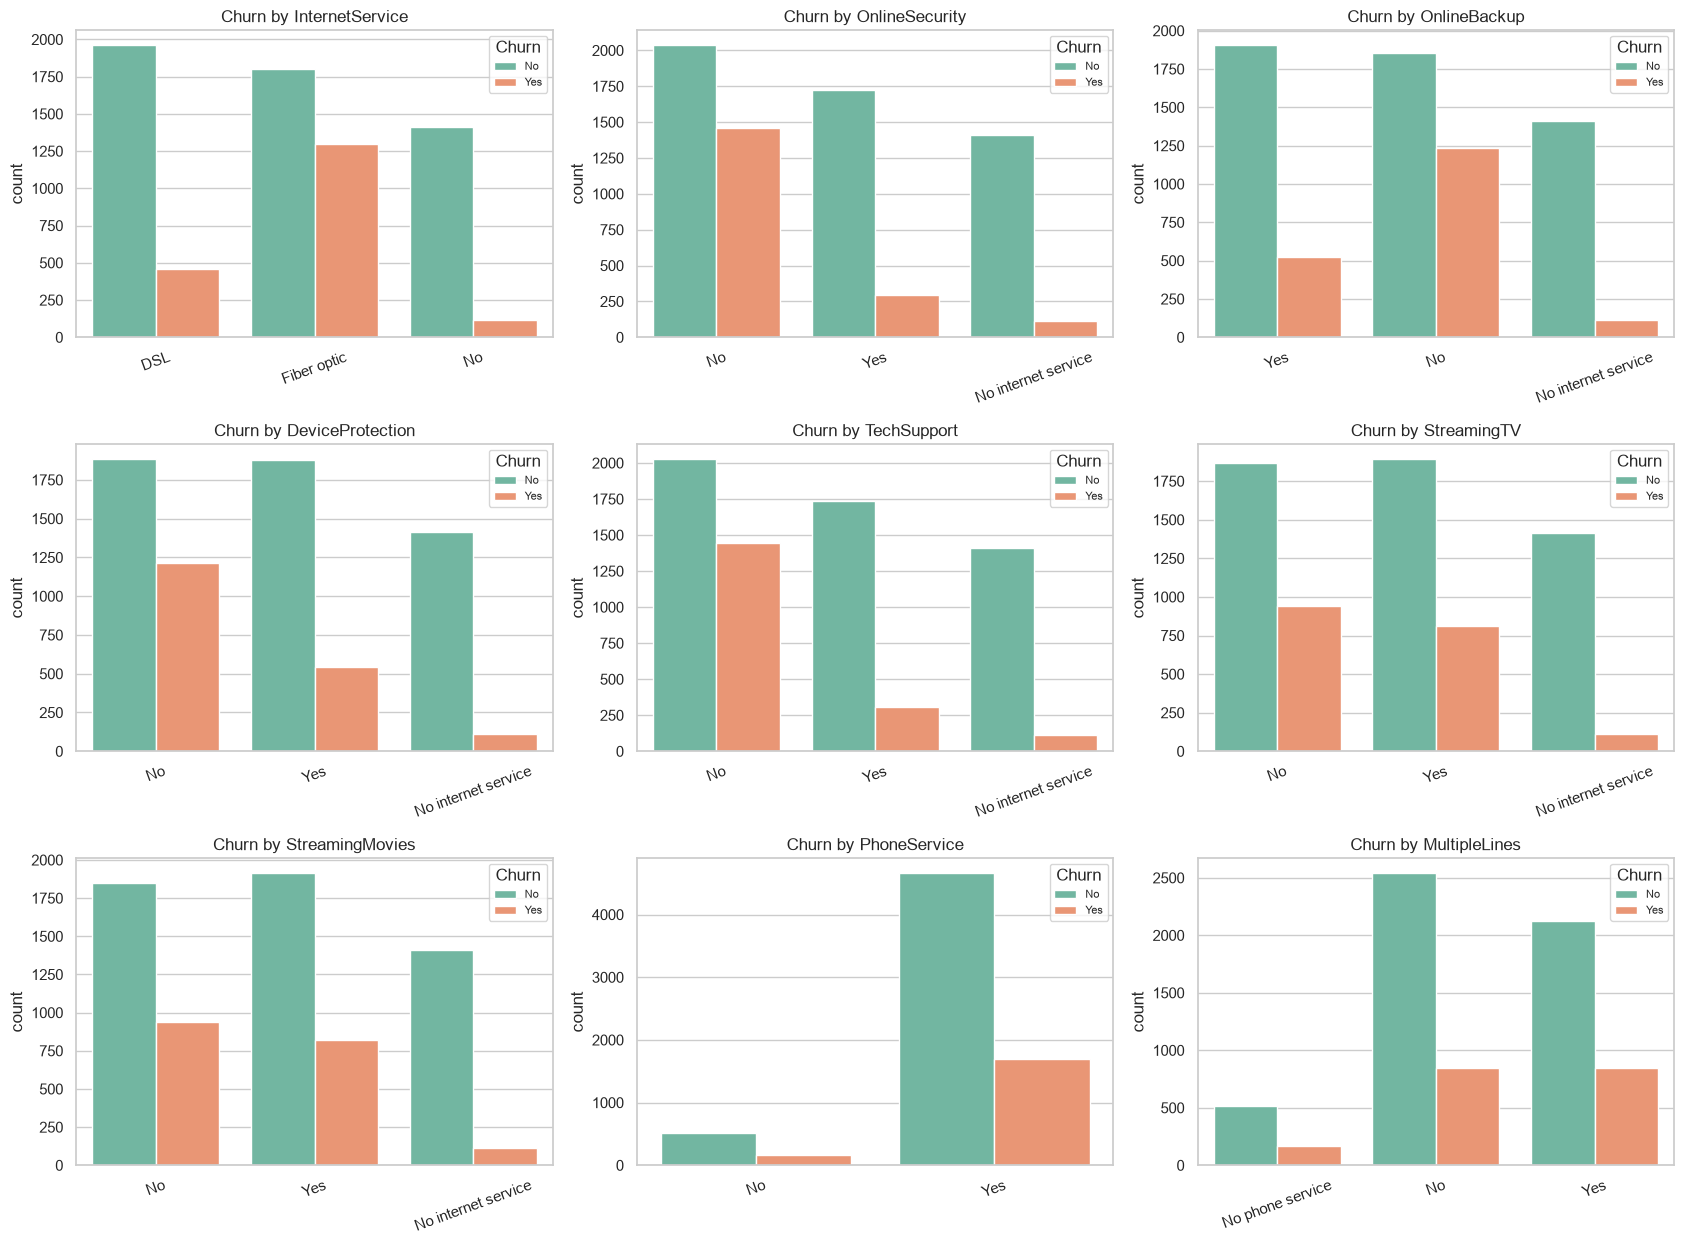

,Feature,Category,Churn rate (%)
1,InternetService,Fiber optic,41.89
3,OnlineSecurity,No,41.77
12,TechSupport,No,41.64
6,OnlineBackup,No,39.93
9,DeviceProtection,No,39.13
18,StreamingMovies,No,33.68
15,StreamingTV,No,33.52
17,StreamingTV,Yes,30.07
20,StreamingMovies,Yes,29.94
25,MultipleLines,Yes,28.61


In [10]:
service_columns = [
    c for c in [
        "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies", "PhoneService", "MultipleLines"
    ] if c in df.columns
]

ncols = 3
nrows = int(np.ceil(len(service_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4.2 * nrows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, service_columns):
    sns.countplot(data=df, x=feature, hue="Churn", ax=ax)
    ax.set_title(f"Churn by {feature}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Churn", fontsize=8)

for ax in axes[len(service_columns):]:
    ax.remove()
plt.tight_layout()
plt.show()

service_rates = []
for feature in service_columns:
    rates = df.groupby(feature, dropna=False)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
    for group, rate in rates.items():
        service_rates.append({"Feature": feature, "Category": str(group), "Churn rate (%)": rate})
service_rate_df = pd.DataFrame(service_rates).sort_values("Churn rate (%)", ascending=False)
display(service_rate_df.round(2))

## 8. Payment method and billing

Payment method may help identify customer groups that need onboarding or payment-experience improvements.

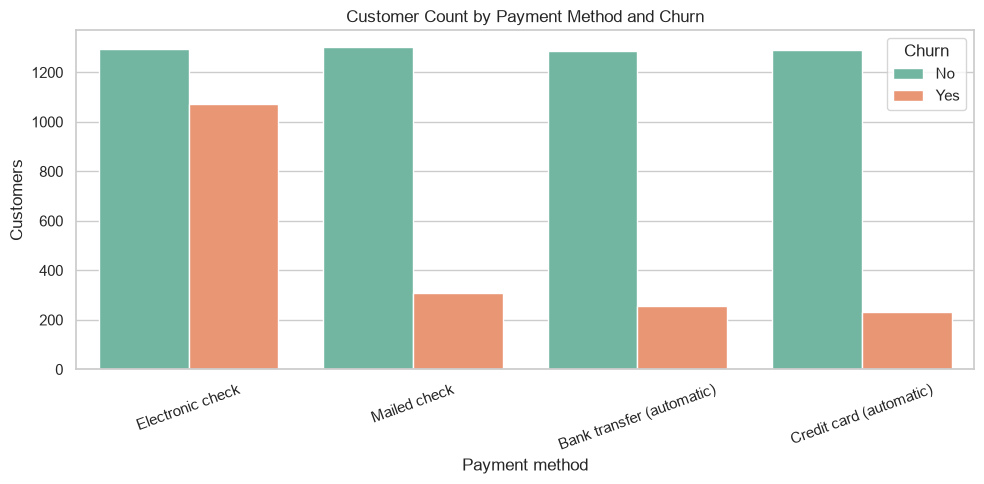

Churn,Stayed (%),Churned (%)
PaymentMethod,,
Electronic check,54.71,45.29
Mailed check,80.89,19.11
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24


Churn rate by paperless billing:


Churn,Stayed (%),Churned (%)
PaperlessBilling,,
Yes,66.43,33.57
No,83.67,16.33


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn", ax=ax)
ax.set_title("Customer Count by Payment Method and Churn")
ax.set_xlabel("Payment method")
ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

display(churn_rate_table(df, "PaymentMethod").round(2))

if "PaperlessBilling" in df.columns:
    print("Churn rate by paperless billing:")
    display(churn_rate_table(df, "PaperlessBilling").round(2))

## 9. Monthly charges and total charges

Compare distributions between churn groups. Total charges are strongly influenced by tenure, so interpret them alongside tenure rather than in isolation.

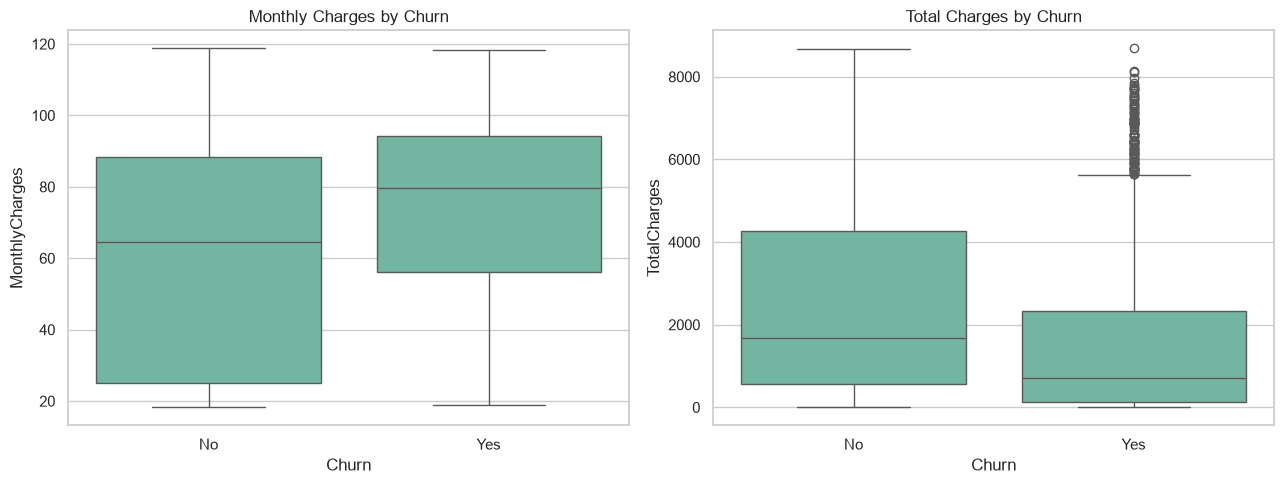

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57  38.00          61.27  64.43     2,549.91 1,679.52
Yes    17.98  10.00          74.44  79.65     1,531.80   703.55

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Monthly Charges by Churn")
sns.boxplot(data=df, x="Churn", y="TotalCharges", order=["No", "Yes"], ax=axes[1])
axes[1].set_title("Total Charges by Churn")
plt.tight_layout()
plt.show()

display(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(2))

## 10. Key findings and business recommendations

The source notebook's visual analysis highlighted these patterns. Re-run the notebook to validate the exact group-level rates for the CSV you use.

1. **Churn is a material retention issue:** the original analysis reported approximately **26.54%** churn.
2. **Contract type:** month-to-month customers appeared more likely to churn than customers on longer contracts.
3. **Tenure:** churn was concentrated among newer customers, while longer-tenure customers were more likely to stay.
4. **Internet and support services:** the original charts suggested higher churn among fiber-optic customers and customers without selected security/support/protection add-ons.
5. **Payment method:** electronic-check customers appeared more likely to churn.
6. **Customer profile:** the original analysis suggested a higher churn share among senior citizens; validate using within-group churn rates rather than raw counts.

### Recommended next steps
- Test an early-tenure onboarding and check-in programme.
- Investigate the reasons for churn among month-to-month customers and consider suitable longer-term plan offers.
- Review fiber-optic customer experience, pricing, installation and support issues.
- Promote relevant support/security add-ons based on customer needs, and measure whether take-up is associated with improved retention.
- Review payment friction for electronic-check customers and test alternative payment nudges.
- Track churn rate by cohort monthly to see whether interventions improve outcomes.

These recommendations are hypotheses to test, not causal conclusions from this EDA.

## 11. Limitations and next steps

- This notebook is descriptive EDA; no predictive model is trained.
- Group differences can reflect other variables, and association does not imply causation.
- Validate the data-cleaning assumption for blank `TotalCharges` if using a different dataset version.
- Next analytical step: build a clearly separated churn prediction workflow with a train/test split, baseline model, suitable metrics (recall, precision, ROC-AUC), leakage checks and an explanation of business trade-offs.

In [13]:
# Compact KPI summary for quick reference
kpis = pd.DataFrame({
    "Metric": ["Customers", "Churned customers", "Stayed customers", "Overall churn rate"],
    "Value": [
        f"{len(df):,}",
        f"{df['Churn'].eq('Yes').sum():,}",
        f"{df['Churn'].eq('No').sum():,}",
        f"{df['Churn'].eq('Yes').mean() * 100:.2f}%"
    ]
})
display(kpis)

,Metric,Value
0,Customers,"7,043"
1,Churned customers,"1,869"
2,Stayed customers,"5,174"
3,Overall churn rate,26.54%
